In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import seaborn as sns

In [2]:
# Load dataset
iris_df = sns.load_dataset("iris")

print(iris_df["species"].value_counts())

print("First 5 rows of dataset:")
print(iris_df.head())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64
First 5 rows of dataset:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


In [3]:
# Data Preprocessing
X = iris_df.drop('species', axis=1)

In [4]:
# Standardize data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

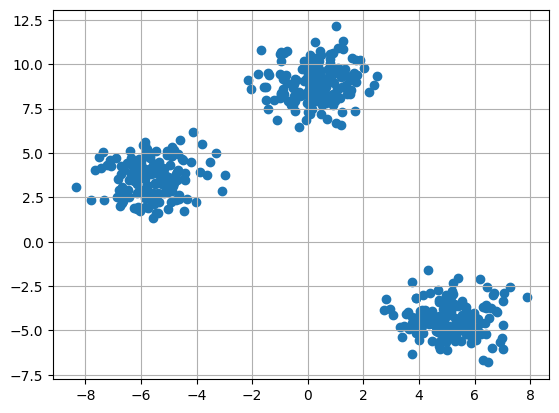

In [5]:
# Generate sample blobs
from sklearn.datasets import make_blobs

X, y = make_blobs(
    n_samples=500,
    n_features=2,
    centers=3,
    random_state=23
)
fig = plt.figure(0)
plt.grid(True)
plt.scatter(X[:, 0], X[:, 1])
plt.show()

In [6]:
# Apply Elbow Method
inertia = []

K = range(1, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

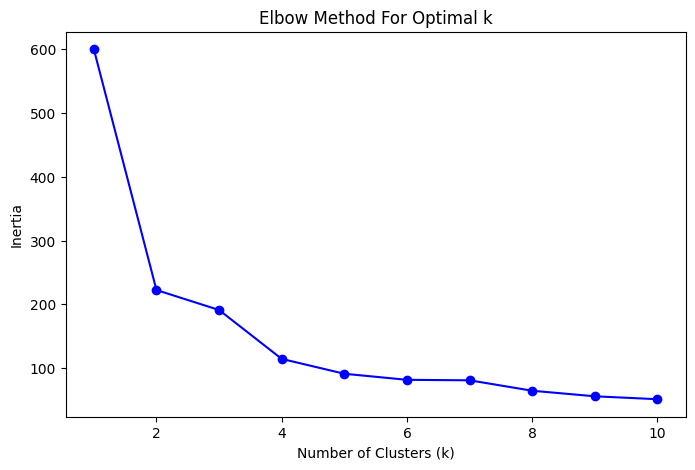

In [7]:
# Plot Elbow Graph
plt.figure(figsize=(8, 5))

plt.plot(K, inertia, 'bo-')

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method For Optimal k')

plt.show()

In [8]:
# Apply K-Means Clustering
kmeans = KMeans(n_clusters=3, random_state=42)

iris_df['Cluster'] = kmeans.fit_predict(X_scaled)

print("\nCluster labels added:")
print(iris_df.head())


Cluster labels added:
   sepal_length  sepal_width  petal_length  petal_width species  Cluster
0           5.1          3.5           1.4          0.2  setosa        1
1           4.9          3.0           1.4          0.2  setosa        2
2           4.7          3.2           1.3          0.2  setosa        2
3           4.6          3.1           1.5          0.2  setosa        2
4           5.0          3.6           1.4          0.2  setosa        1


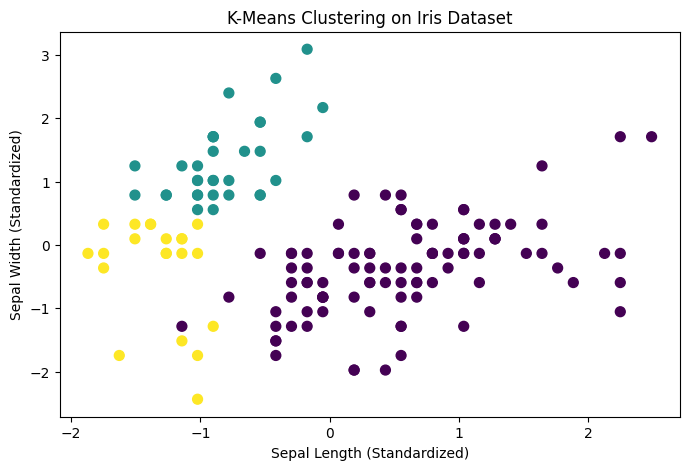

In [9]:
# Visualization using first two features
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=iris_df['Cluster'],
    cmap='viridis',
    s=50
)

plt.title("K-Means Clustering on Iris Dataset")
plt.xlabel("Sepal Length (Standardized)")
plt.ylabel("Sepal Width (Standardized)")

plt.show()

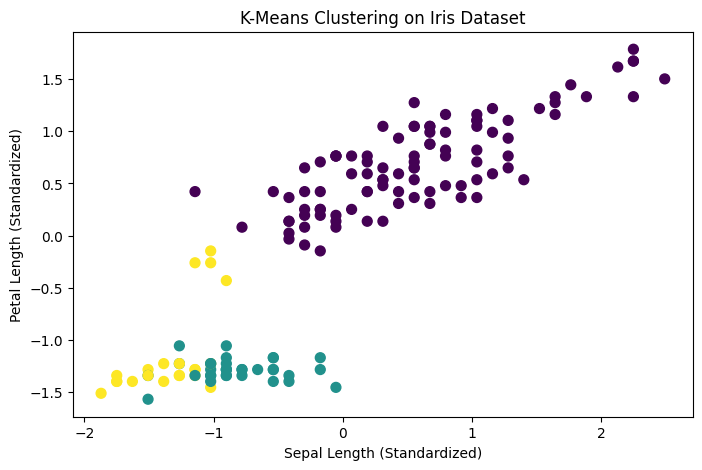

In [10]:
# Visualization using first and third features
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 2],
    c=iris_df['Cluster'],
    cmap='viridis',
    s=50
)

plt.title("K-Means Clustering on Iris Dataset")
plt.xlabel("Sepal Length (Standardized)")
plt.ylabel("Petal Length (Standardized)")

plt.show()

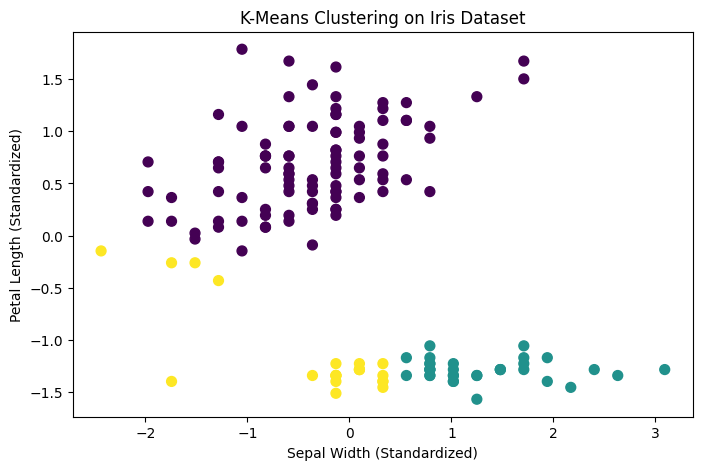

In [11]:
# Visualization using second and third features
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 1],
    X_scaled[:, 2],
    c=iris_df['Cluster'],
    cmap='viridis',
    s=50
)
plt.title("K-Means Clustering on Iris Dataset")
plt.xlabel("Sepal Width (Standardized)")
plt.ylabel("Petal Length (Standardized)")

plt.show()